# DSCI 552 - Homework 5

Name: Gao Wang  
GitHub Username: Gavinfornever  
USC ID: 8103152166

Run all cells from the repository root. The analysis uses only relative data paths and keeps printed results compact for the 20-page submission limit.

In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from xgboost import XGBRegressor

SEED = 552
DATA = Path("data")
plt.rcParams.update({"figure.dpi": 95, "axes.grid": True, "grid.alpha": 0.2,
                     "font.size": 9, "savefig.bbox": "tight"})


## 1. Decision trees as interpretable models

### (a) Load Acute Inflammations

Each row has six symptoms and two diagnosis labels. The supplied file is UTF-16 encoded; temperature uses a decimal comma. The two outputs are fit jointly by a multi-output decision tree.

In [2]:
acute_columns = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
                 "micturition_pain", "urethra_burning", "bladder_inflammation",
                 "renal_pelvis_nephritis"]
acute = pd.read_csv(DATA / "diagnosis.data", sep="\t", header=None,
                    encoding="utf-16", names=acute_columns)
acute["temperature"] = acute["temperature"].str.replace(",", ".", regex=False).astype(float)
for column in acute_columns[1:]:
    acute[column] = acute[column].str.strip().map({"yes": 1, "no": 0})
assert acute.shape == (120, 8) and not acute.isna().any().any()
X_acute = acute.iloc[:, :6]
y_acute = acute.iloc[:, 6:]
display(pd.DataFrame({"rows": [len(acute)], "predictors": [X_acute.shape[1]],
                      "labels": [y_acute.shape[1]], "unique_label_pairs": [len(y_acute.drop_duplicates())]}))


,rows,predictors,labels,unique_label_pairs
0,120,6,2,4


### (b)-(c) Full decision tree and its IF-THEN rules

The full tree is trained on the entire data set as requested. A leaf's two predictions are the two diagnoses. Rules are extracted directly from every root-to-leaf path, so they exactly describe the plotted tree.

Full tree: depth=4, leaves=6, training exact-match accuracy=1.000


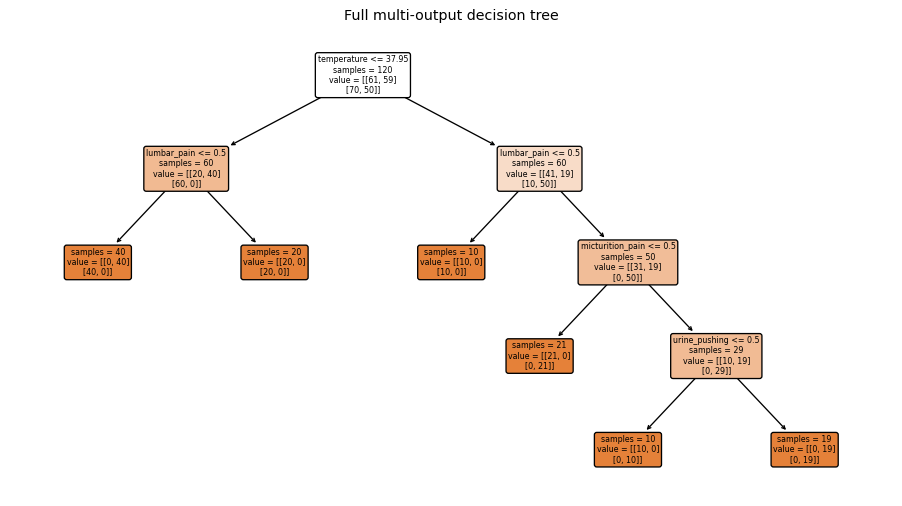

Full-tree IF-THEN rules:
01. IF temperature <= 37.95 AND lumbar_pain <= 0.50 THEN bladder_inflammation=yes, renal_pelvis_nephritis=no
02. IF temperature <= 37.95 AND lumbar_pain > 0.50 THEN bladder_inflammation=no, renal_pelvis_nephritis=no
03. IF temperature > 37.95 AND lumbar_pain <= 0.50 THEN bladder_inflammation=no, renal_pelvis_nephritis=no
04. IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pain <= 0.50 THEN bladder_inflammation=no, renal_pelvis_nephritis=yes
05. IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pain > 0.50 AND urine_pushing <= 0.50 THEN bladder_inflammation=no, renal_pelvis_nephritis=yes
06. IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pain > 0.50 AND urine_pushing > 0.50 THEN bladder_inflammation=yes, renal_pelvis_nephritis=yes


In [3]:
# AI prompt (scope: tree-to-rule conversion): "Turn each root-to-leaf path of the fitted two-label decision tree into an IF-THEN rule, keeping the numerical split thresholds and both diagnosis predictions."
def tree_rules(model, feature_names, label_names):
    tree = model.tree_
    rules = []
    def visit(node, conditions):
        if tree.feature[node] == _tree.TREE_UNDEFINED:
            prediction = np.empty(model.n_outputs_, dtype=int)
            for output in range(model.n_outputs_):
                prediction[output] = model.classes_[output][np.argmax(tree.value[node, output])]
            conclusion = ", ".join(f"{name}={'yes' if value == 1 else 'no'}"
                                   for name, value in zip(label_names, prediction))
            rules.append("IF " + (" AND ".join(conditions) or "TRUE") + " THEN " + conclusion)
            return
        feature = feature_names[tree.feature[node]]
        threshold = tree.threshold[node]
        visit(tree.children_left[node], conditions + [f"{feature} <= {threshold:.2f}"])
        visit(tree.children_right[node], conditions + [f"{feature} > {threshold:.2f}"])
    visit(0, [])
    return rules


full_tree = DecisionTreeClassifier(random_state=SEED).fit(X_acute, y_acute)
print(f"Full tree: depth={full_tree.get_depth()}, leaves={full_tree.get_n_leaves()}, "
      f"training exact-match accuracy={full_tree.score(X_acute, y_acute):.3f}")
fig, ax = plt.subplots(figsize=(12, 6.4))
plot_tree(full_tree, feature_names=X_acute.columns, filled=True,
          rounded=True, fontsize=6, impurity=False, ax=ax)
ax.set_title("Full multi-output decision tree")
plt.show()
full_rules = tree_rules(full_tree, list(X_acute.columns), list(y_acute.columns))
print("Full-tree IF-THEN rules:")
for number, rule in enumerate(full_rules, start=1):
    print(f"{number:02d}. {rule}")


### (d) Cost-complexity pruning

Five-fold shuffled CV compares unique pruning values. The one-standard-error rule selects the largest pruning value whose mean CV accuracy is within one standard error of the best; this favors a smaller interpretable tree. CV is used only to select pruning strength, then the tree is refit on all 120 records.

,alpha,cv_mean,cv_se,leaves
0,0.0000,0.9833,0.0167,6
1,0.0491,0.8583,0.0449,4
2,0.0795,0.7417,0.0534,3
3,0.1111,0.6250,0.0874,2
4,0.2042,0.3500,0.0860,1


Selected alpha=0.00000, CV accuracy=0.983, leaves=6, training accuracy=1.000.


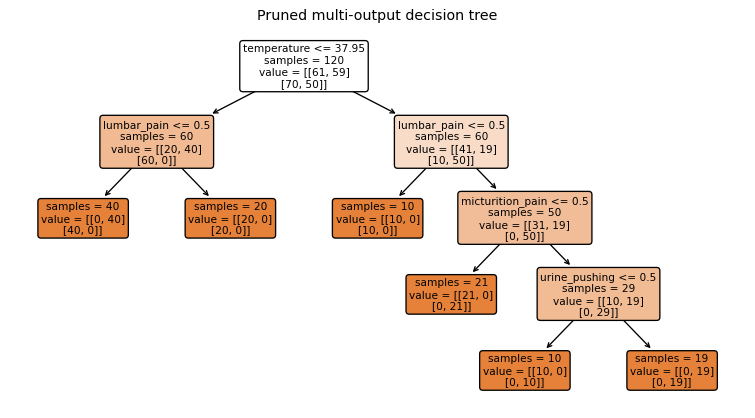

Pruned-tree IF-THEN rules:
01. IF temperature <= 37.95 AND lumbar_pain <= 0.50 THEN bladder_inflammation=yes, renal_pelvis_nephritis=no
02. IF temperature <= 37.95 AND lumbar_pain > 0.50 THEN bladder_inflammation=no, renal_pelvis_nephritis=no
03. IF temperature > 37.95 AND lumbar_pain <= 0.50 THEN bladder_inflammation=no, renal_pelvis_nephritis=no
04. IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pain <= 0.50 THEN bladder_inflammation=no, renal_pelvis_nephritis=yes
05. IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pain > 0.50 AND urine_pushing <= 0.50 THEN bladder_inflammation=no, renal_pelvis_nephritis=yes
06. IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pain > 0.50 AND urine_pushing > 0.50 THEN bladder_inflammation=yes, renal_pelvis_nephritis=yes


In [4]:
pruning_path = full_tree.cost_complexity_pruning_path(X_acute, y_acute)
alphas = np.unique(pruning_path.ccp_alphas)
cv_tree = KFold(n_splits=5, shuffle=True, random_state=SEED)
pruning_rows = []
for alpha in alphas:
    scores = cross_val_score(DecisionTreeClassifier(ccp_alpha=float(alpha), random_state=SEED),
                             X_acute, y_acute, cv=cv_tree, scoring="accuracy")
    fitted = DecisionTreeClassifier(ccp_alpha=float(alpha), random_state=SEED).fit(X_acute, y_acute)
    pruning_rows.append({"alpha": alpha, "cv_mean": scores.mean(),
                         "cv_se": scores.std(ddof=1) / np.sqrt(len(scores)),
                         "leaves": fitted.get_n_leaves()})
pruning_summary = pd.DataFrame(pruning_rows)
best_index = pruning_summary["cv_mean"].idxmax()
cutoff = pruning_summary.loc[best_index, "cv_mean"] - pruning_summary.loc[best_index, "cv_se"]
eligible = pruning_summary.loc[pruning_summary["cv_mean"] >= cutoff]
selected = eligible.sort_values(["leaves", "alpha"], ascending=[True, False]).iloc[0]
pruned_tree = DecisionTreeClassifier(ccp_alpha=float(selected["alpha"]), random_state=SEED).fit(X_acute, y_acute)
display(pruning_summary.round(4))
print(f"Selected alpha={selected['alpha']:.5f}, CV accuracy={selected['cv_mean']:.3f}, "
      f"leaves={pruned_tree.get_n_leaves()}, training accuracy={pruned_tree.score(X_acute, y_acute):.3f}.")
fig, ax = plt.subplots(figsize=(10, 5.2))
plot_tree(pruned_tree, feature_names=X_acute.columns, filled=True,
          rounded=True, fontsize=8, impurity=False, ax=ax)
ax.set_title("Pruned multi-output decision tree")
plt.show()
print("Pruned-tree IF-THEN rules:")
for number, rule in enumerate(tree_rules(pruned_tree, list(X_acute.columns), list(y_acute.columns)), 1):
    print(f"{number:02d}. {rule}")


## 2. The LASSO and boosting for regression

### (a)-(b) Data, fixed split, missing values, nonpredictive columns

The first 1,495 rows are training data; the remaining rows are held out. `state`, `county`, `community`, `communityname`, and `fold` identify communities rather than predict the target. Columns entirely missing in training cannot be imputed and are removed. For all model comparisons, a median imputer is fitted on the training folds through a pipeline, preventing validation leakage.

In [5]:
description = (DATA / "communities.names").read_text(encoding="latin-1")
column_names = re.findall(r"^@attribute\s+(\S+)", description, flags=re.MULTILINE)
crime = pd.read_csv(DATA / "communities.data", header=None, names=column_names, na_values="?")
assert crime.shape == (1994, 128)
target = "ViolentCrimesPerPop"
nonpredictive = ["state", "county", "community", "communityname", "fold"]
predictor_columns = [name for name in crime if name not in nonpredictive + [target]]
train_raw = crime.iloc[:1495]
test_raw = crime.iloc[1495:]
all_missing_train = train_raw[predictor_columns].columns[train_raw[predictor_columns].isna().all()].tolist()
predictor_columns = [name for name in predictor_columns if name not in all_missing_train]
X_train = train_raw[predictor_columns].apply(pd.to_numeric)
X_test = test_raw[predictor_columns].apply(pd.to_numeric)
y_train = train_raw[target].astype(float)
y_test = test_raw[target].astype(float)
assert not y_train.isna().any() and not y_test.isna().any()
print(f"Data: {crime.shape}; train/test: {len(X_train)}/{len(X_test)}; "
      f"usable features: {len(predictor_columns)}; fully missing train columns: {all_missing_train}.")
print(f"Missing predictor cells (train/test): {X_train.isna().sum().sum()}/{X_test.isna().sum().sum()}.")


Data: (1994, 128); train/test: 1495/499; usable features: 122; fully missing train columns: [].
Missing predictor cells (train/test): 27633/9218.


### (c) Feature correlation matrix

The heatmap summarizes all usable predictors; labels are omitted to keep the 100+ feature plot legible on a printed page. The highest-CV features are named in the next section.

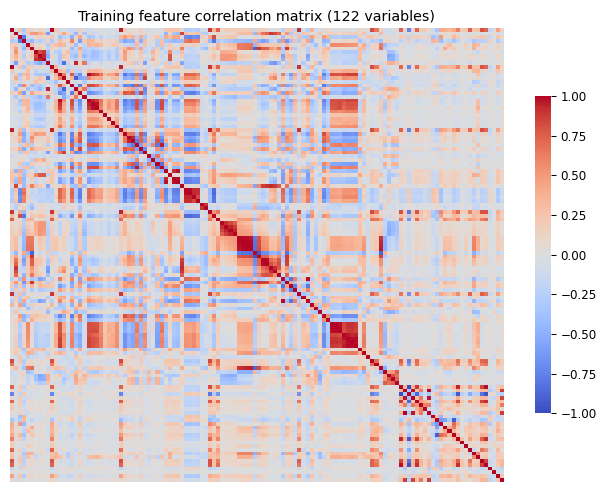

In [6]:
train_imputer = SimpleImputer(strategy="median").fit(X_train)
X_train_imputed = pd.DataFrame(train_imputer.transform(X_train), columns=predictor_columns)
correlation = X_train_imputed.corr()
fig, ax = plt.subplots(figsize=(8.4, 6.2))
sns.heatmap(correlation, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title(f"Training feature correlation matrix ({len(predictor_columns)} variables)")
plt.show()


### (d)-(e) Coefficient of variation and exploratory plots

CV is sample standard deviation divided by the mean. It is computed on the training set after median imputation. The table includes all usable variables; the plots show the floor of the square root of 128, which is 11. Visual association does not establish statistical significance or causality because of noise, multiple comparisons, and correlations among predictors.

Finite CV values: 122 of 122; top 11:


,mean,sample_sd,CV
PctPolicAsian,0.016,0.090,5.527
NumStreet,0.023,0.099,4.293
NumInShelters,0.030,0.103,3.471
NumIlleg,0.037,0.114,3.059
NumImmig,0.031,0.090,2.927
LemasPctOfficDrugUn,0.093,0.238,2.553
NumUnderPov,0.057,0.133,2.342
LemasSwornFT,0.029,0.065,2.248
population,0.058,0.130,2.241
numbUrban,0.065,0.132,2.038


All feature CV values (alphabetical):


,feature 1,CV 1,feature 2,CV 2,feature 3,CV 3,feature 4,CV 4
0,AsianPerCap,0.615,FemalePctDiv,0.360,HispPerCap,0.484,HousVacant,1.968
1,LandArea,1.645,LemasGangUnitDeploy,0.335,LemasPctOfficDrugUn,2.553,LemasPctPolicOnPatr,0.112
2,LemasSwFTFieldOps,0.064,LemasSwFTFieldPerPop,0.286,LemasSwFTPerPop,0.344,LemasSwornFT,2.248
3,LemasTotReqPerPop,0.387,LemasTotalReq,1.452,MalePctDivorce,0.399,MalePctNevMarr,0.404
4,MedNumBR,0.814,MedOwnCostPctInc,0.416,MedOwnCostPctIncNoMtg,0.47,MedRent,0.563
5,MedRentPctHousInc,0.343,MedYrHousBuilt,0.471,NumIlleg,3.059,NumImmig,2.927
6,NumInShelters,3.471,NumKindsDrugsSeiz,0.141,NumStreet,4.293,NumUnderPov,2.342
7,OfficAssgnDrugUnits,1.175,OtherPerCap,0.673,OwnOccHiQuart,0.884,OwnOccLowQuart,0.86
8,OwnOccMedVal,0.889,PctBSorMore,0.593,PctBornSameState,0.336,PctEmplManu,0.514
9,PctEmplProfServ,0.403,PctEmploy,0.351,PctFam2Par,0.333,PctForeignBorn,1.066


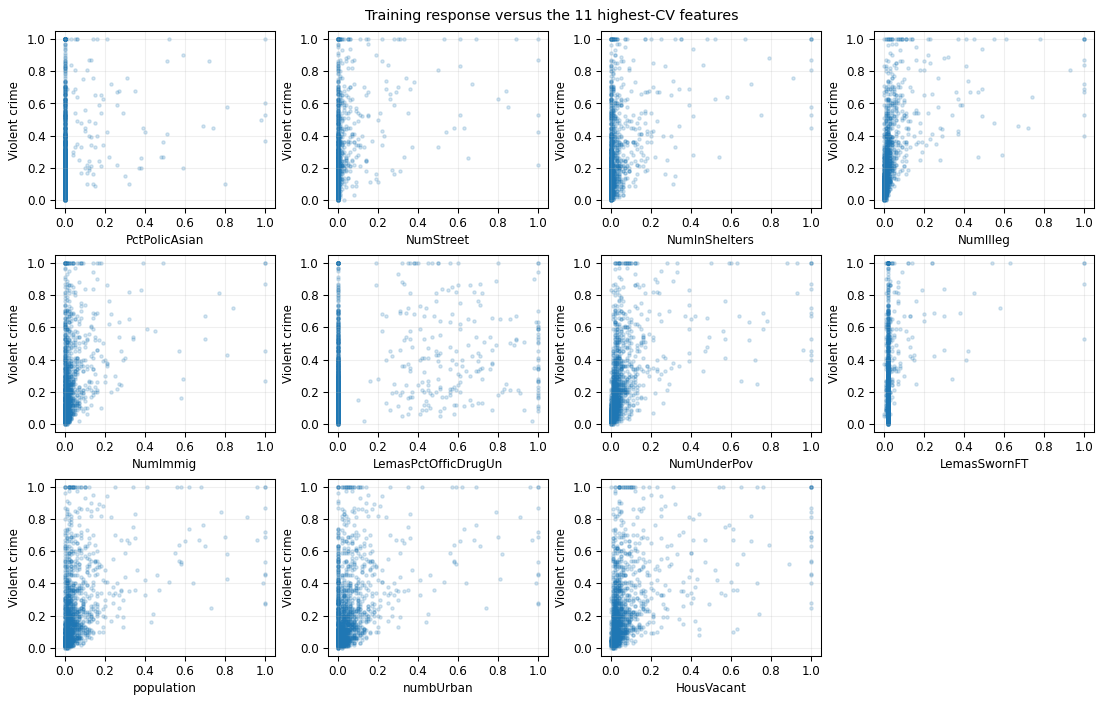

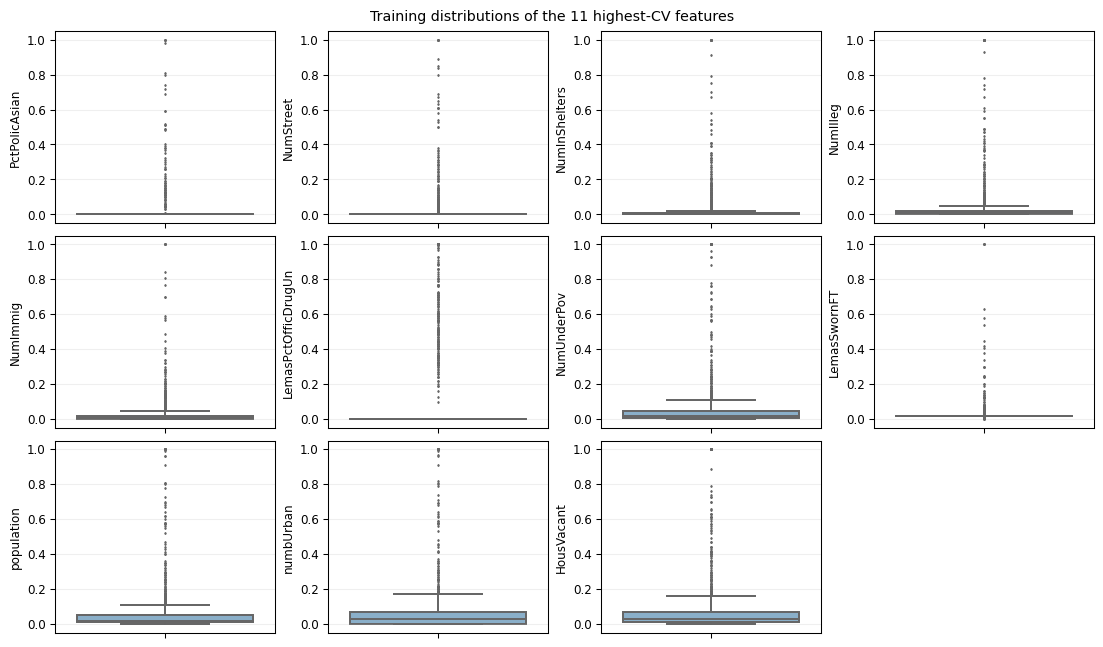

In [7]:
# AI prompt (scope: CV ranking and compact plots): "Compute each training feature's sample SD divided by its mean, select the eleven largest finite CV values, and plot each against the response plus a compact box plot."
means = X_train_imputed.mean()
stds = X_train_imputed.std(ddof=1)
cv_values = (stds / means.replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)
cv_table = pd.DataFrame({"mean": means, "sample_sd": stds, "CV": cv_values})
top_features = cv_values.nlargest(int(np.floor(np.sqrt(128)))).index.tolist()
print(f"Finite CV values: {cv_values.notna().sum()} of {len(cv_values)}; top {len(top_features)}:")
display(cv_table.loc[top_features].round(3))
print("All feature CV values (alphabetical):")
cv_items = list(cv_values.sort_index().items())
cv_rows = []
for offset in range(0, len(cv_items), 4):
    row = {}
    for position, (name, value) in enumerate(cv_items[offset:offset + 4], start=1):
        row[f"feature {position}"] = name
        row[f"CV {position}"] = round(value, 3)
    cv_rows.append(row)
display(pd.DataFrame(cv_rows).fillna(""))

fig, axes = plt.subplots(3, 4, figsize=(11.5, 7.3), constrained_layout=True)
for ax, feature in zip(axes.flat, top_features):
    ax.scatter(X_train_imputed[feature], y_train.to_numpy(), alpha=0.18, s=6)
    ax.set(xlabel=feature, ylabel="Violent crime")
for ax in list(axes.flat)[len(top_features):]:
    ax.axis("off")
fig.suptitle("Training response versus the 11 highest-CV features")
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(11.5, 6.7), constrained_layout=True)
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(y=X_train_imputed[feature], ax=ax, color="#80b1d3", fliersize=1)
    ax.set(xlabel="", ylabel=feature)
for ax in list(axes.flat)[len(top_features):]:
    ax.axis("off")
fig.suptitle("Training distributions of the 11 highest-CV features")
plt.show()


### (f)-(i) Least squares, ridge, LASSO, and PCR

Test error is mean squared error. Three-fold shuffled CV selects ridge/LASSO penalty and PCR component count on training data only. LASSO is fit both with the original normalized inputs and with a StandardScaler; the latter changes how the L1 penalty treats features with different sample variance. The final test set is never used to choose a tuning value.

In [8]:
reg_cv = KFold(n_splits=3, shuffle=True, random_state=SEED)
results = []


def report_model(name, model, selected=None):
    model.fit(X_train, y_train)
    error = mean_squared_error(y_test, model.predict(X_test))
    results.append({"model": name, "test_MSE": error, "chosen_parameter": selected})
    return model


ols = report_model("OLS", Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("regress", LinearRegression())]), "none")

# AI prompt (scope: training-only regression CV): "Tune ridge, raw and standardized LASSO, and PCR with imputation and scaling inside each CV training fold, then report held-out MSE and selected variables."
def choose_by_cv(builder, candidates):
    scores = []
    for candidate in candidates:
        fold_mse = -cross_val_score(builder(candidate), X_train, y_train, cv=reg_cv,
                                   scoring="neg_mean_squared_error", n_jobs=-1)
        scores.append((candidate, fold_mse.mean()))
    return sorted(scores, key=lambda item: (item[1], item[0]))[0]


ridge_alphas = np.logspace(-3, 3, 13)
ridge_choice, ridge_cv_mse = choose_by_cv(
    lambda a: Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler()), ("regress", Ridge(alpha=a))]), ridge_alphas)
ridge = report_model("Ridge", Pipeline([("impute", SimpleImputer(strategy="median")),
                                        ("scale", StandardScaler()),
                                        ("regress", Ridge(alpha=ridge_choice))]), f"alpha={ridge_choice:.4g}")

lasso_alphas = np.logspace(-5, -1, 13)
lasso_models = {}
for use_scaler in [False, True]:
    label = "LASSO standardized" if use_scaler else "LASSO original scale"
    def make_lasso(alpha):
        steps = [("impute", SimpleImputer(strategy="median"))]
        if use_scaler:
            steps.append(("scale", StandardScaler()))
        steps.append(("regress", Lasso(alpha=alpha, max_iter=30000, tol=1e-3)))
        return Pipeline(steps)
    alpha, cv_mse = choose_by_cv(make_lasso, lasso_alphas)
    model = report_model(label, make_lasso(alpha), f"alpha={alpha:.5g}")
    selected = [name for name, beta in zip(predictor_columns, model.named_steps["regress"].coef_)
                if abs(beta) > 1e-7]
    lasso_models[label] = model
    print(f"{label}: {len(selected)} nonzero variables: {', '.join(selected)}")

component_grid = [1, 2, 3, 5, 8, 12, 20, 30, 45, 60, 80, 100, min(120, len(predictor_columns))]
component_grid = sorted(set(n for n in component_grid if n <= len(predictor_columns)))
def pcr_builder(components):
    return Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler()),
                     ("pca", PCA(n_components=components, svd_solver="full")),
                     ("regress", LinearRegression())])
pcr_components, pcr_cv_mse = choose_by_cv(pcr_builder, component_grid)
pcr = report_model("PCR", pcr_builder(pcr_components), f"M={pcr_components}")
display(pd.DataFrame(results).round(5))
print(f"Training-CV MSE: Ridge={ridge_cv_mse:.5f}; PCR={pcr_cv_mse:.5f}.")


LASSO original scale: 75 nonzero variables: racepctblack, racePctAsian, agePct12t21, agePct12t29, agePct65up, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctBSorMore, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctSameCity85, LemasSwFTFieldPerPop, LemasTotalReq, PolicReqPerOffic, RacialMatchCommPol, PctPolicBlack, PctPolicHisp, 

,model,test_MSE,chosen_parameter
0,OLS,0.01797,none
1,Ridge,0.01740,alpha=100
2,LASSO original scale,0.01765,alpha=0.0001
3,LASSO standardized,0.01764,alpha=0.001
4,PCR,0.01835,M=60


Training-CV MSE: Ridge=0.01969; PCR=0.02029.


### (j) L1-regularized gradient boosting tree

XGBoost uses gradient-boosted regression trees with `reg_alpha` as its L1 penalty on leaf weights. This matches the assignment's suggested XGBoost approach; it is not literally a LASSO regression fit within every node. Three-fold training-only CV chooses `reg_alpha` from a small prespecified grid. The model then predicts the untouched test rows.

In [9]:
boost_alphas = [0.0, 0.01, 0.1, 1.0, 10.0]
def boost_builder(alpha):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("boost", XGBRegressor(n_estimators=220, max_depth=3, learning_rate=0.05,
                               subsample=0.85, colsample_bytree=0.85,
                               objective="reg:squarederror", reg_alpha=alpha,
                               n_jobs=1, random_state=SEED, tree_method="hist")),
    ])
boost_alpha, boost_cv_mse = choose_by_cv(boost_builder, boost_alphas)
boost = report_model("XGBoost L1", boost_builder(boost_alpha), f"reg_alpha={boost_alpha:g}")
print(f"Chosen boost CV MSE={boost_cv_mse:.5f}.")
display(pd.DataFrame(results).sort_values("test_MSE").reset_index(drop=True).round(5))


Chosen boost CV MSE=0.01946.


,model,test_MSE,chosen_parameter
0,XGBoost L1,0.01638,reg_alpha=1
1,Ridge,0.01740,alpha=100
2,LASSO standardized,0.01764,alpha=0.001
3,LASSO original scale,0.01765,alpha=0.0001
4,OLS,0.01797,none
5,PCR,0.01835,M=60


## References

- [UCI Acute Inflammations](https://archive.ics.uci.edu/dataset/184/acute+inflammations) and [UCI Communities and Crime](https://archive.ics.uci.edu/dataset/183/communities+and+crime); the actual data files are included in this repository.
- [scikit-learn cost-complexity pruning](https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html), [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html), [PCR example](https://scikit-learn.org/stable/auto_examples/cross_decomposition/plot_pcr_vs_pls.html).
- [XGBoost tree parameters](https://xgboost.readthedocs.io/en/stable/parameter.html), including `reg_alpha`.
